# Cross-Sectional Momentum in US Equities

This notebook investigates whether a stock's **relative past performance** contains information about its subsequent returns.

The project uses a simple monthly long-short momentum strategy on S&P 500 stocks and studies:

- baseline performance
- lookback and portfolio-breadth sensitivity
- turnover and transaction costs
- out-of-sample performance
- statistical significance
- subperiod behavior
- return autocorrelation

> **Research question:** Does cross-sectional equity momentum generate persistent market-neutral alpha after transaction costs and across different time periods and signal specifications?

**Important:** This is a student research project. The goal is to understand the process of quantitative strategy research rather than build a production trading system.

## 1. Setup

The analysis uses Python, pandas, NumPy, matplotlib, SciPy, yfinance, and requests.

In [1]:
import os
from io import StringIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yfinance as yf
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:.4f}")

## 2. Data Collection

The stock universe is the **current S&P 500 constituent list** obtained from Wikipedia.

I use `yfinance` for historical prices. `auto_adjust=True` is used so that the `Close` series incorporates historical price adjustments.

The downloaded price history covers January 2009 through December 2025.

In [2]:
# Get current S&P 500 constituents
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url, headers=headers)
response.raise_for_status()

sp500_df = pd.read_html(StringIO(response.text))[0]

tickers = (
    sp500_df["Symbol"]
    .str.replace(".", "-", regex=False)
    .tolist()
)

print("Number of stocks:", len(tickers))
print("First 10 tickers:", tickers[:10])

Number of stocks: 503
First 10 tickers: ['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


In [3]:
prices = yf.download(
    tickers,
    start="2009-01-01",
    end="2026-01-01",
    auto_adjust=True,
    group_by="column",
    threads=True
)

print("Downloaded data shape:", prices.shape)

[**********************74%***********            ]  372 of 503 completed$HONA: Data doesn't exist for startDate = 1230786000, endDate = 1767243600
[**********************78%************           ]  392 of 503 completed$FDXF: Data doesn't exist for startDate = 1230786000, endDate = 1767243600
[**********************89%******************     ]  450 of 503 completed$KVUE: possibly delisted; no price data found  (1d 2009-01-01 -> 2026-01-01)
[**********************90%******************     ]  452 of 503 completed$AWK: possibly delisted; no price data found  (1d 2009-01-01 -> 2026-01-01)
[**********************90%******************     ]  455 of 503 completed$L: possibly delisted; no price data found  (1d 2009-01-01 -> 2026-01-01)
[*********************100%***********************]  503 of 503 completed

5 Failed downloads:
['HONA', 'FDXF']: Data doesn't exist for startDate = 1230786000, endDate = 1767243600
['KVUE', 'AWK', 'L']: possibly delisted; no price data found  (1d 2009-01-01 -> 202

Downloaded data shape: (4276, 2520)


## 3. Price Data Preparation

Only the adjusted `Close` prices are needed for the momentum strategy.

Stocks have different listing histories, so missing observations are expected. I do **not** forward-fill the entire dataset or drop every stock with any missing value. Instead, stocks are evaluated for eligibility at each rebalance date.

In [4]:
close = prices["Close"].copy().sort_index()

print("Price matrix shape:", close.shape)
print("\nMissing fraction for a few stocks:")
print(close.isna().mean().sort_values(ascending=False).head(10))
history_start = close.notna().idxmax()

print("\nLatest-starting stocks:")
print(history_start.sort_values().tail(10))

Price matrix shape: (4276, 503)

Missing fraction for a few stocks:
Ticker
KVUE   1.0000
AWK    1.0000
L      1.0000
HONA   1.0000
FDXF   1.0000
Q      0.9892
SNDK   0.9481
GEV    0.8964
SOLV   0.8962
RDDT   0.8955
dtype: float64

Latest-starting stocks:
Ticker
APP    2021-04-15
HOOD   2021-07-29
CEG    2022-01-19
GEHC   2022-12-15
VLTO   2023-10-04
RDDT   2024-03-21
SOLV   2024-03-26
GEV    2024-03-27
SNDK   2025-02-13
Q      2025-10-27
dtype: datetime64[s]


In [5]:
# Convert daily prices to month-end prices
month_end_prices = close.resample("ME").last()

print("Monthly price matrix:", month_end_prices.shape)
print(month_end_prices.head())

Monthly price matrix: (204, 503)
Ticker           A   AAPL  ABBV  ABNB     ABT   ACGL     ACN    ADBE     ADI  \
Date                                                                           
2009-01-31 11.4216 2.6958   NaN   NaN 17.9317 6.3552 22.7073 19.3100 13.2450   
2009-02-28  8.7620 2.6712   NaN   NaN 15.3118 5.7054 21.0021 16.7000 12.3566   
2009-03-31  9.7096 3.1441   NaN   NaN 15.4282 5.6906 19.7790 21.3900 12.9159   
2009-04-30 11.5353 3.7635   NaN   NaN 13.6602 6.1048 21.1748 27.3500 14.2631   
2009-05-31 11.5163 4.0620   NaN   NaN 14.7080 6.0033 21.5346 28.1800 16.5005   

Ticker         ADM  ...     WY    WYNN     XEL     XOM  XYL  XYZ     YUM  \
Date                ...                                                    
2009-01-31 17.0789  ... 5.5975 17.9321  9.9148 40.1447  NaN  NaN 14.6266   
2009-02-28 16.7117  ... 4.9464 12.4892  9.5281 35.8206  NaN  NaN 13.4307   
2009-03-31 17.4138  ... 5.6446 11.9050 10.1346 35.9261  NaN  NaN 14.0440   
2009-04-30 15.4329  ... 7.

## 4. Momentum Signal

The baseline signal is **12–1 month momentum**:
$$
Momentum_t = \frac{P_{t-1}}{P_{t-12}} - 1
$$

The most recent month is excluded. Therefore, the portfolio formed at the end of month \(t\) uses information through month \(t-1\).

This separation between signal formation and the following holding period is important for avoiding look-ahead bias.

In [6]:
momentum_12_1 = (
    month_end_prices.shift(1) /
    month_end_prices.shift(12)
    - 1
)

# Other lookback specifications used later
momentum_3_1 = (
    month_end_prices.shift(1) /
    month_end_prices.shift(3)
    - 1
)

momentum_6_1 = (
    month_end_prices.shift(1) /
    month_end_prices.shift(6)
    - 1
)

momentum = momentum_12_1

### Example Signal

As a sanity check, the following shows the highest and lowest momentum stocks at one historical rebalance date. These rankings are only used to inspect the signal; they are not manually selected for the strategy.

In [7]:
example_date = "2020-12-31"
example_signal = momentum_12_1.loc[example_date].dropna()

print("Top 10 momentum stocks:")
display(example_signal.nlargest(10).to_frame("Momentum"))

print("\nBottom 10 momentum stocks:")
display(example_signal.nsmallest(10).to_frame("Momentum"))

Top 10 momentum stocks:


,Momentum
Ticker,
MRNA,6.8088
TSLA,5.7841
XYZ,2.3721
BE,2.2825
CRWD,2.0736
CVNA,1.7182
DDOG,1.6183
NVDA,1.2813
GNRC,1.1434



Bottom 10 momentum stocks:


,Momentum
Ticker,
NCLH,-0.6085
OXY,-0.6054
CCL,-0.6023
FANG,-0.5542
APA,-0.4886
UAL,-0.4886
OKE,-0.4715
WFC,-0.4712
SLB,-0.4681


## 5. Portfolio Construction and Backtest

At each monthly rebalance:

1. Rank stocks by momentum.
2. Buy the top 10%.
3. Short the bottom 10%.
4. Equal-weight positions within each side.
5. Maintain +100% long exposure and -100% short exposure.
6. Hold the portfolio until the next month-end.

The portfolio is therefore approximately dollar-neutral with 200% gross exposure.

If a selected stock has a missing holding-period return, the long and short sides are independently renormalized so that valid positions retain their intended exposure.

In [8]:
def run_momentum_backtest(momentum_signal, close, month_end_prices, cutoff=0.10,
                           return_weights=False):
    monthly_returns = {}
    portfolio_weights = {}

    rebalance_dates = momentum_signal.index

    for i in range(len(rebalance_dates) - 1):
        rebalance_date = rebalance_dates[i]
        next_date = rebalance_dates[i + 1]

        signal = momentum_signal.loc[rebalance_date].dropna()

        if len(signal) < 10:
            continue

        n_side = int(len(signal) * cutoff)

        if n_side == 0:
            continue

        long_stocks = signal.nlargest(n_side).index
        short_stocks = signal.nsmallest(n_side).index

        weights = pd.Series(0.0, index=close.columns)
        weights.loc[long_stocks] = 1 / len(long_stocks)
        weights.loc[short_stocks] = -1 / len(short_stocks)

        start_prices = month_end_prices.loc[rebalance_date]
        end_prices = month_end_prices.loc[next_date]
        stock_returns = end_prices / start_prices - 1

        valid = stock_returns.notna()
        valid_weights = weights[valid].copy()

        long_mask = valid_weights > 0
        short_mask = valid_weights < 0

        if long_mask.any():
            valid_weights.loc[long_mask] /= valid_weights.loc[long_mask].sum()

        if short_mask.any():
            valid_weights.loc[short_mask] /= -valid_weights.loc[short_mask].sum()

        portfolio_return = (
            valid_weights * stock_returns[valid]
        ).sum()

        monthly_returns[next_date] = portfolio_return

        if return_weights:
            portfolio_weights[rebalance_date] = valid_weights

    returns = pd.Series(monthly_returns, name="portfolio_return")

    if return_weights:
        weights_df = pd.DataFrame(portfolio_weights).T.fillna(0)
        return returns, weights_df

    return returns

In [9]:
# Baseline strategy: 12–1 momentum, top/bottom 10%
monthly_returns, portfolio_weights = run_momentum_backtest(
    momentum_12_1,
    close,
    month_end_prices,
    cutoff=0.10,
    return_weights=True
)

print("Backtest months:", len(monthly_returns))
print("First return:", monthly_returns.index.min())
print("Last return:", monthly_returns.index.max())

Backtest months: 191
First return: 2010-02-28 00:00:00
Last return: 2025-12-31 00:00:00


### Simple Timing Sanity Check

The December 2020 signal determines the January 2021 portfolio. This is a simple check that the signal date and holding-period return are separated.

In [10]:
signal = momentum_12_1.loc["2020-12-31"].dropna()
n_side = int(len(signal) * 0.10)

long_stocks = signal.nlargest(n_side).index
short_stocks = signal.nsmallest(n_side).index

weights = pd.Series(0.0, index=close.columns)
weights.loc[long_stocks] = 1 / len(long_stocks)
weights.loc[short_stocks] = -1 / len(short_stocks)

jan_returns = (
    month_end_prices.loc["2021-01-31"] /
    month_end_prices.loc["2020-12-31"] - 1
)

portfolio_return = (weights * jan_returns).sum()

print(f"January 2021 portfolio return: {portfolio_return:.2%}")
print(f"Net exposure: {weights.sum():.2f}")
print(f"Gross exposure: {weights.abs().sum():.2f}")

January 2021 portfolio return: 3.84%
Net exposure: 0.00
Gross exposure: 2.00


## 6. Performance Metrics

The Sharpe ratio below uses monthly returns, assumes a 0% risk-free rate, and annualizes by multiplying the monthly Sharpe by \(\sqrt{12}\).

In [11]:
def calculate_metrics(returns):
    returns = returns.dropna()

    annualized_return = (
        (1 + returns).prod() ** (12 / len(returns)) - 1
    )
    annualized_volatility = returns.std() * np.sqrt(12)

    sharpe = (
        returns.mean() /
        returns.std()
    ) * np.sqrt(12)

    cumulative = (1 + returns).cumprod()
    running_max = cumulative.cummax()
    drawdown = cumulative / running_max - 1

    return {
        "Annualized Return": annualized_return,
        "Annualized Volatility": annualized_volatility,
        "Sharpe": sharpe,
        "Max Drawdown": drawdown.min(),
    }

baseline_metrics = calculate_metrics(monthly_returns)
pd.Series(baseline_metrics, name="Baseline")

Annualized Return        0.0163
Annualized Volatility    0.1778
Sharpe                   0.1807
Max Drawdown            -0.5210
Name: Baseline, dtype: float64

## 7. Baseline Results

The baseline strategy is a 12–1 month momentum signal with top/bottom 10% portfolio breadth.

In [12]:
baseline_table = pd.DataFrame(
    {"Gross": baseline_metrics}
)

baseline_table

,Gross
Annualized Return,0.0163
Annualized Volatility,0.1778
Sharpe,0.1807
Max Drawdown,-0.5210


In [13]:
# Annual strategy returns
annual_returns = monthly_returns.resample("YE").apply(
    lambda x: (1 + x).prod() - 1
)

annual_returns.to_frame("Annual Return")

,Annual Return
2010-12-31,0.2110
2011-12-31,0.0294
2012-12-31,0.0006
2013-12-31,0.1667
2014-12-31,-0.0611
2015-12-31,0.2203
2016-12-31,-0.2778
2017-12-31,0.0121
2018-12-31,0.1066
2019-12-31,-0.0860


## 8. Robustness: Momentum Lookback

I compare 3–1, 6–1, and 12–1 month momentum signals to see how sensitive the results are to the lookback choice.

In [14]:
lookback_signals = {
    "3-1": momentum_3_1,
    "6-1": momentum_6_1,
    "12-1": momentum_12_1,
}

lookback_results = {}

for name, signal in lookback_signals.items():
    returns = run_momentum_backtest(
        signal,
        close,
        month_end_prices,
        cutoff=0.10
    )
    lookback_results[name] = calculate_metrics(returns)

lookback_table = pd.DataFrame(lookback_results).T
lookback_table

,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown
3-1,-0.0396,0.1576,-0.1776,-0.5342
6-1,-0.0002,0.1664,0.0822,-0.3744
12-1,0.0163,0.1778,0.1807,-0.5210


## 9. Robustness: Portfolio Breadth

The baseline selects the top and bottom 10%. I also test 5% and 20% to see how concentration affects the results.

In [15]:
breadth_results = {}

for cutoff in [0.05, 0.10, 0.20]:
    returns = run_momentum_backtest(
        momentum_12_1,
        close,
        month_end_prices,
        cutoff=cutoff
    )

    breadth_results[f"{int(cutoff * 100)}%"] = calculate_metrics(returns)

breadth_table = pd.DataFrame(breadth_results).T
breadth_table

,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown
5%,0.0430,0.2305,0.2998,-0.5560
10%,0.0163,0.1778,0.1807,-0.5210
20%,0.0161,0.1370,0.1854,-0.3657


## 10. Turnover and Transaction Costs

Turnover is calculated as:

$$
Turnover_t = \frac{1}{2}\sum_i |w_{i,t} - w_{i,t-1}|
$$

I then apply simple proportional transaction-cost assumptions of 10, 25, and 50 basis points per unit of turnover.

These are sensitivity assumptions rather than a complete market-impact model.

In [16]:
turnover = (
    portfolio_weights.diff()
    .abs()
    .sum(axis=1) / 2
).iloc[1:]

print(f"Average monthly turnover: {turnover.mean():.2%}")
print(f"Median monthly turnover: {turnover.median():.2%}")
print(f"Maximum monthly turnover: {turnover.max():.2%}")

Average monthly turnover: 55.99%
Median monthly turnover: 55.10%
Maximum monthly turnover: 127.08%


In [17]:
cost_rates = {
    "Gross": 0.0000,
    "10 bps": 0.0010,
    "25 bps": 0.0025,
    "50 bps": 0.0050,
}

cost_results = {}

for label, cost_rate in cost_rates.items():
    if cost_rate == 0:
        returns = monthly_returns
    else:
        returns = (
            monthly_returns.loc[turnover.index]
            - turnover * cost_rate
        )

    cost_results[label] = calculate_metrics(returns)

cost_table = pd.DataFrame(cost_results).T
cost_table

,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown
Gross,0.0163,0.1778,0.1807,-0.5210
10 bps,0.0102,0.1783,0.1469,-0.5475
25 bps,0.0000,0.1784,0.0903,-0.5846
50 bps,-0.0167,0.1786,-0.0039,-0.6398


## 11. Out-of-Sample Evaluation

To separate development from evaluation, I use:

- **Development:** 2010–2022
- **Out-of-sample:** 2023–2025

The strategy specification is kept fixed for the OOS evaluation.

In [18]:
development_returns = monthly_returns[
    (monthly_returns.index >= "2010-01-01") &
    (monthly_returns.index <= "2022-12-31")
]

oos_returns = monthly_returns[
    (monthly_returns.index >= "2023-01-01") &
    (monthly_returns.index <= "2025-12-31")
]

print(
    f"Development: {development_returns.index.min().date()} "
    f"to {development_returns.index.max().date()} "
    f"({len(development_returns)} months)"
)

print(
    f"OOS: {oos_returns.index.min().date()} "
    f"to {oos_returns.index.max().date()} "
    f"({len(oos_returns)} months)"
)

oos_table = pd.DataFrame({
    "Development": calculate_metrics(development_returns),
    "OOS 2023–2025": calculate_metrics(oos_returns),
})

oos_table

Development: 2010-02-28 to 2022-12-31 (155 months)
OOS: 2023-01-31 to 2025-12-31 (36 months)


,Development,OOS 2023–2025
Annualized Return,0.0096,0.0456
Annualized Volatility,0.1682,0.2168
Sharpe,0.1416,0.3134
Max Drawdown,-0.4849,-0.1306


In [ ]:
oos_turnover = turnover[
    (turnover.index >= "2022-12-01") &
    (turnover.index <= "2025-11-30")
].copy()

oos_turnover.index = oos_returns.index

oos_cost_results = {}

for label, cost_rate in cost_rates.items():
    if cost_rate == 0:
        returns = oos_returns
    else:
        returns = oos_returns - oos_turnover * cost_rate

    oos_cost_results[label] = calculate_metrics(returns)

oos_cost_table = pd.DataFrame(oos_cost_results).T
oos_cost_table

,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown
Gross,0.0456,0.2168,0.3134,-0.1306
10 bps,0.0390,0.2168,0.2840,-0.1315
25 bps,0.0291,0.2168,0.2399,-0.1328
50 bps,0.0128,0.2167,0.1664,-0.1438


## 12. Statistical Significance of OOS Returns

The OOS sample contains only 36 monthly observations, so the statistical test should be interpreted cautiously.

I test whether the mean monthly OOS return differs from zero using a two-sided t-test.

In [20]:
mean_monthly = oos_returns.mean()
std_monthly = oos_returns.std()
n = len(oos_returns)

standard_error = std_monthly / np.sqrt(n)
t_stat = mean_monthly / standard_error
p_value = 2 * (1 - stats.t.cdf(abs(t_stat), df=n - 1))

critical_value = stats.t.ppf(0.975, df=n - 1)
ci_low = mean_monthly - critical_value * standard_error
ci_high = mean_monthly + critical_value * standard_error

significance_table = pd.Series({
    "Mean Monthly Return": mean_monthly,
    "Monthly Standard Deviation": std_monthly,
    "Standard Error": standard_error,
    "t-statistic": t_stat,
    "p-value": p_value,
    "95% CI Lower": ci_low,
    "95% CI Upper": ci_high,
    "Observations": n,
}, name="OOS Statistical Analysis")

significance_table

Mean Monthly Return           0.0057
Monthly Standard Deviation    0.0626
Standard Error                0.0104
t-statistic                   0.5427
p-value                       0.5907
95% CI Lower                 -0.0155
95% CI Upper                  0.0268
Observations                 36.0000
Name: OOS Statistical Analysis, dtype: float64

## 13. Subperiod Analysis

To understand whether the strategy behaves similarly across different periods, I split the full sample into three subperiods.

In [21]:
subperiods = {
    "2010–2015": monthly_returns[
        (monthly_returns.index >= "2010-01-01") &
        (monthly_returns.index <= "2015-12-31")
    ],
    "2016–2020": monthly_returns[
        (monthly_returns.index >= "2016-01-01") &
        (monthly_returns.index <= "2020-12-31")
    ],
    "2021–2025": monthly_returns[
        (monthly_returns.index >= "2021-01-01") &
        (monthly_returns.index <= "2025-12-31")
    ],
}

subperiod_table = pd.DataFrame({
    period: calculate_metrics(returns)
    for period, returns in subperiods.items()
}).T

subperiod_table

,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown
2010–2015,0.0902,0.1322,0.7214,-0.1498
2016–2020,-0.0779,0.2014,-0.3014,-0.3346
2021–2025,0.0308,0.1984,0.2528,-0.3050


## 14. Return Autocorrelation

I check autocorrelation at several lags as a basic diagnostic of serial dependence in the monthly return series.

In [22]:
lags = [1, 3, 6, 12]

autocorrelation_table = pd.DataFrame({
    "Full Sample": [
        monthly_returns.autocorr(lag=lag)
        for lag in lags
    ],
    "OOS": [
        oos_returns.autocorr(lag=lag)
        for lag in lags
    ],
}, index=lags)

autocorrelation_table.index.name = "Lag"
autocorrelation_table

,Full Sample,OOS
Lag,,
1,-0.0642,0.0290
3,-0.0222,0.0308
6,0.0750,0.0048
12,0.0690,-0.2338


## 15. Visualizations

The following figures are the main visual summaries used in the README.

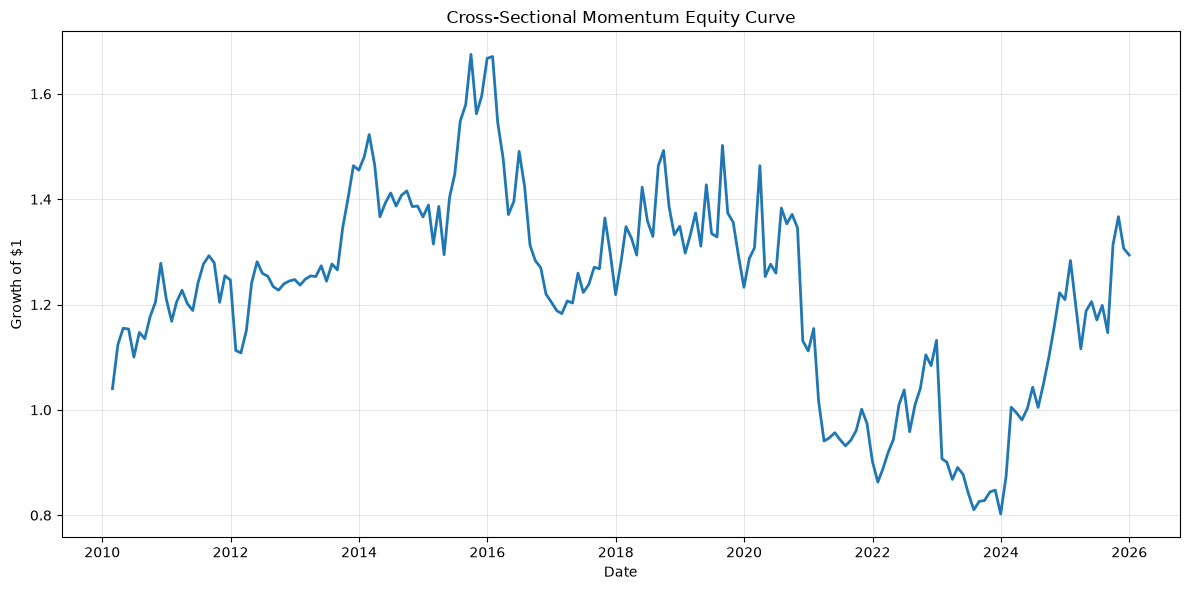

In [23]:
# Equity curve
equity_curve = (1 + monthly_returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(equity_curve, linewidth=2)
plt.title("Cross-Sectional Momentum Equity Curve")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/equity_curve.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

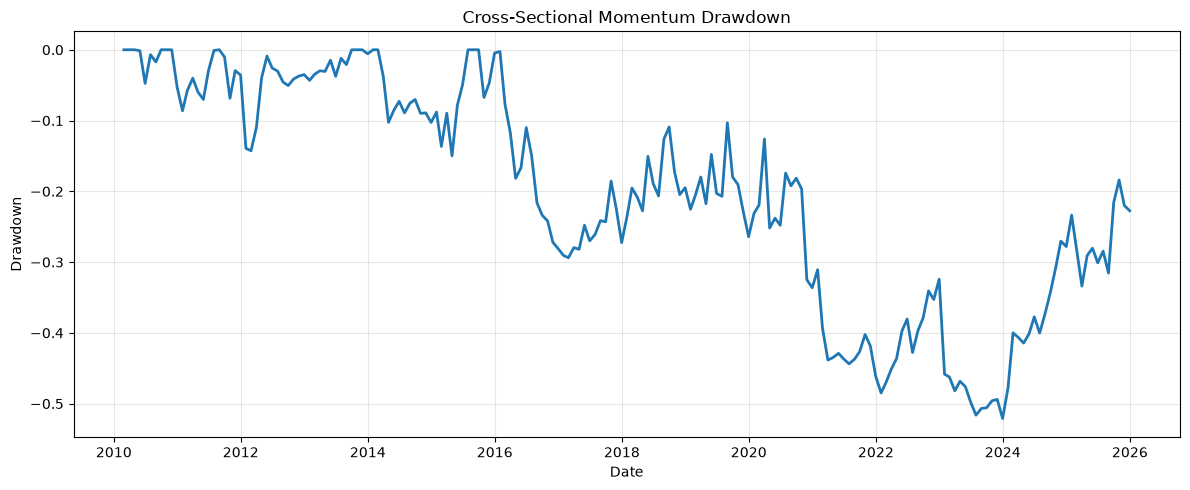

In [24]:
# Drawdown
running_max = equity_curve.cummax()
drawdown = equity_curve / running_max - 1

plt.figure(figsize=(12, 5))
plt.plot(drawdown, linewidth=2)
plt.title("Cross-Sectional Momentum Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/drawdown.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

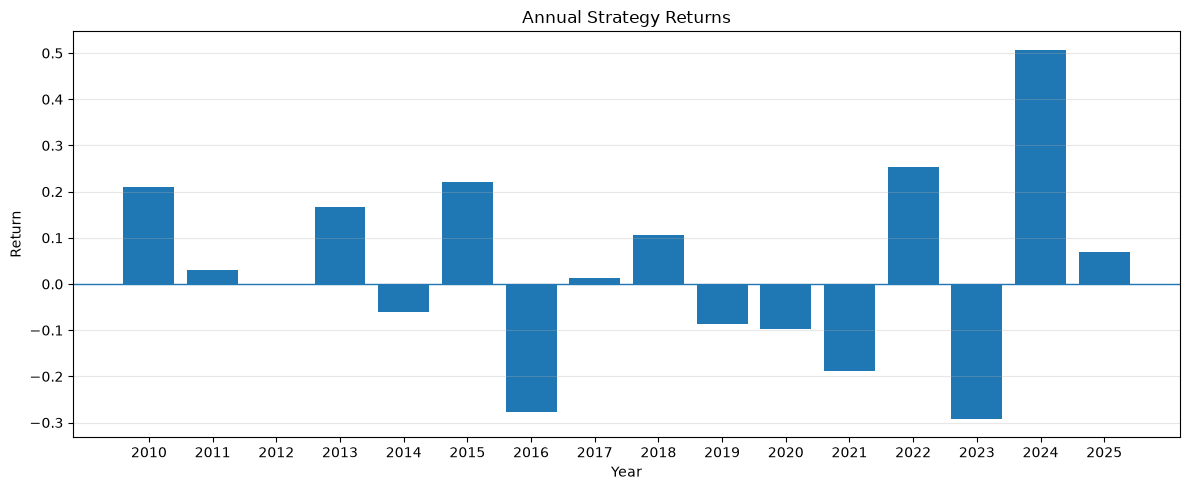

In [25]:
# Annual returns
plt.figure(figsize=(12, 5))
plt.bar(
    annual_returns.index.year.astype(str),
    annual_returns.values
)
plt.title("Annual Strategy Returns")
plt.xlabel("Year")
plt.ylabel("Return")
plt.axhline(0, linewidth=1)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("results/annual_returns.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

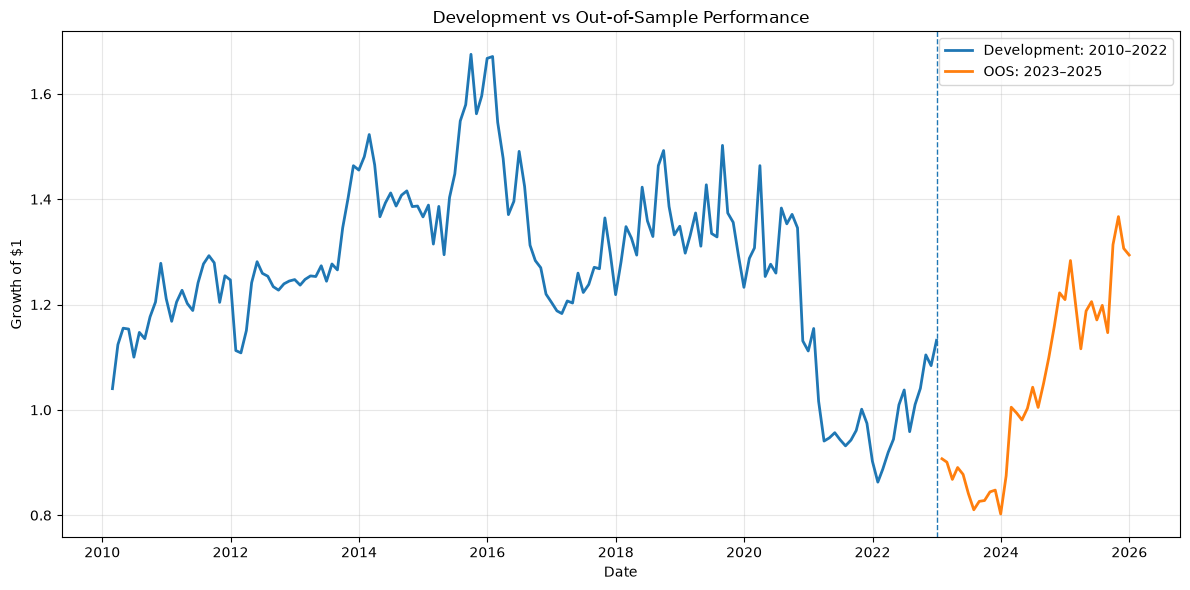

In [26]:
# Development vs OOS
development_equity = (1 + development_returns).cumprod()
oos_equity = (1 + oos_returns).cumprod()

oos_equity_continuous = (
    oos_equity * development_equity.iloc[-1]
)

plt.figure(figsize=(12, 6))

plt.plot(
    development_equity.index,
    development_equity.values,
    linewidth=2,
    label="Development: 2010–2022"
)

plt.plot(
    oos_equity_continuous.index,
    oos_equity_continuous.values,
    linewidth=2,
    label="OOS: 2023–2025"
)

plt.axvline(
    pd.Timestamp("2023-01-01"),
    linestyle="--",
    linewidth=1
)

plt.title("Development vs Out-of-Sample Performance")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "results/development_vs_oos.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

## 16. Final Summary

The baseline 12–1 month cross-sectional momentum strategy produced modest positive gross returns over the full sample, but results were sensitive to transaction costs, lookback period, portfolio breadth, and market period.

The 2023–2025 OOS period produced positive gross returns, but the sample contains only 36 observations and the mean monthly return was not statistically distinguishable from zero.

The main lesson from the project is that a positive backtest is only a starting point. Timing, implementation costs, robustness, statistical uncertainty, and out-of-sample evaluation are all important when evaluating a systematic strategy.

### Main limitations

- The historical universe uses **current S&P 500 constituents**, creating survivorship bias.
- Yahoo Finance is not an institutional market-data source.
- Transaction costs are modeled simply and do not include market impact, borrow costs, financing, or short-sale constraints.
- The OOS period is relatively short.